# Preparación del subconjunto EuroSAT RGB

Preparamos los datos del proyecto **Ojo en órbita**. Partimos de 27.000 imágenes de 64 × 64 píxeles y buscamos un subconjunto equilibrado de **800 imágenes por clase: 8.000 en total**.

Primero filtramos la redundancia visual mediante dHash y después completamos la reducción con muestreo aleatorio por clase.

In [2]:
from pathlib import Path

import pandas as pd

### Imágenes disponibles por clase

Construimos la tabla `inventory` que contiene la ruta y la clase de cada imagen. Ordenamos las carpetas y los archivos para mantener un recorrido reproducible.

Comparamos las imágenes disponibles (`available`) con el objetivo de 800 (`target`). La columna `surplus` indica cuántas sobran respecto a ese objetivo.

In [4]:
RGB_DIR = Path("data/EuroSAT_RGB")
IMAGES_PER_CLASS = 800

if not RGB_DIR.is_dir():
    raise FileNotFoundError(f"Directory not found")

records = []

for class_dir in sorted(RGB_DIR.iterdir()):
    if not class_dir.is_dir():
        continue

    for image_path in sorted(class_dir.glob("*.jpg")):
        records.append({
            "path": image_path.as_posix(),
            "class_name": class_dir.name,
        })

inventory = pd.DataFrame(records, columns=["path", "class_name"])

summary = (
    inventory.groupby("class_name")
    .size()
    .rename("available")
    .to_frame()
)

summary["target"] = IMAGES_PER_CLASS
summary["surplus"] = summary["available"] - summary["target"]

display(summary)
print(f"Total images: {len(inventory):,}")

,available,target,surplus
class_name,,,
AnnualCrop,3000,800,2200
Forest,3000,800,2200
HerbaceousVegetation,3000,800,2200
Highway,2500,800,1700
Industrial,2500,800,1700
Pasture,2000,800,1200
PermanentCrop,2500,800,1700
Residential,3000,800,2200
River,2500,800,1700


Total images: 27,000


## Análisis de redundancia visual

### Huellas dHash y distancia de Hamming

Con dHash resumimos la estructura de luminosidad de cada imagen en **64 bits**. La convertimos a gris, la reducimos a **9 columnas × 8 filas** y comparamos cada píxel con su vecino derecho. Guardamos 1 si el vecino es más claro y 0 en caso contrario. Obtenemos 8 comparaciones por fila y 8 filas.

Usamos el filtro **LANCZOS** para calcular los píxeles reducidos combinando información de varios píxeles originales. El proceso es determinista y resume toda la imagen.

Con la **distancia de Hamming** contamos las posiciones distintas entre dos huellas. Su valor va de 0 a 64. Una distancia pequeña indica huellas similares. Sin embargo, incluso dos huellas iguales pueden corresponder a imágenes diferentes ya que ahora hemos perdido color y detalle.

In [5]:
import numpy as np
from PIL import Image


def compute_dhash(image_path):
    with Image.open(image_path) as image:
        small_image = image.convert("L").resize(
            (9, 8),
            Image.Resampling.LANCZOS,
        )
        pixels = np.asarray(small_image)

    differences = pixels[:, 1:] > pixels[:, :-1]

    return differences.flatten()


def hamming_distance(hash_a, hash_b):
    return int(np.count_nonzero(hash_a != hash_b))

### Comprobación con dos imágenes

In [6]:
first_path = inventory.iloc[0]["path"]
second_path = inventory.iloc[1]["path"]

first_hash = compute_dhash(first_path)
second_hash = compute_dhash(second_path)

print("First image:", first_path)
print("Second image:", second_path)
print("First hash:", first_hash.astype(int))
print("Hash length:", first_hash.size)
print("Self-distance:", hamming_distance(first_hash, first_hash))
print("Pair distance:", hamming_distance(first_hash, second_hash))

First image: data/EuroSAT_RGB/AnnualCrop/AnnualCrop_1.jpg
Second image: data/EuroSAT_RGB/AnnualCrop/AnnualCrop_10.jpg
First hash: [0 0 0 1 1 0 0 1 1 1 0 0 1 0 0 1 1 1 0 0 1 0 1 0 1 1 0 0 0 0 1 0 0 1 1 1 1
 0 0 0 0 1 1 1 1 0 0 0 0 1 1 1 1 0 0 0 0 1 1 1 1 0 0 0]
Hash length: 64
Self-distance: 0
Pair distance: 39


### Visualización del redimensionado y de los bits

Comparamos la imagen en gris con dos versiones de 9 × 8 píxeles. Con **NEAREST** tomamos un píxel cercano para cada posición de salida y con **LANCZOS** combinamos información de varios. En el último panel vemos las 64 comparaciones de la versión LANCZOS.

Usamos `interpolation="nearest"` únicamente para mostrar los píxeles como bloques en la figura.


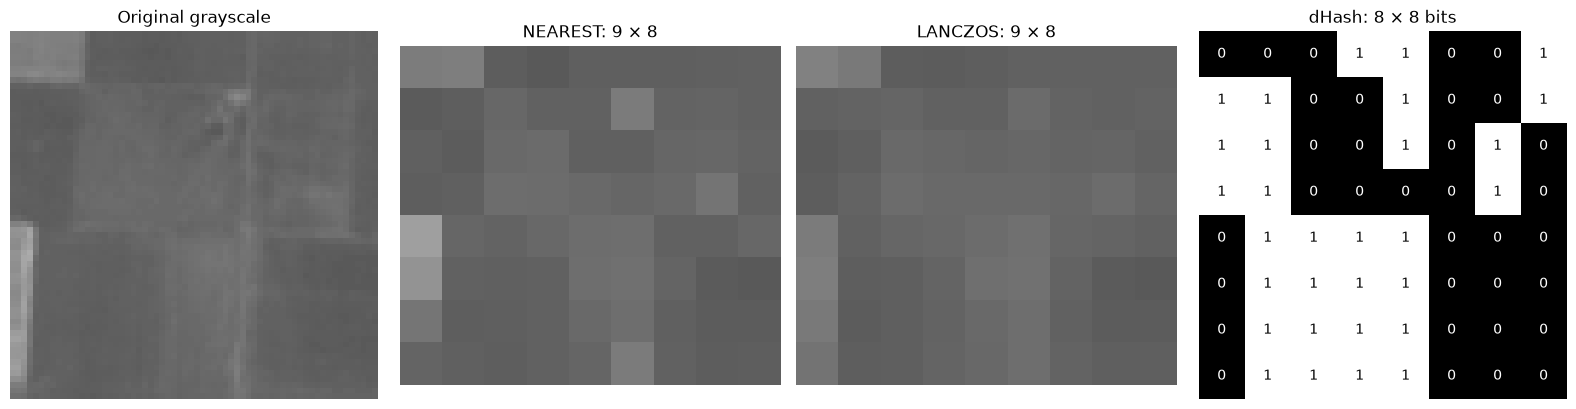

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

image_path = inventory.iloc[0]["path"]

with Image.open(image_path) as image:
    gray_image = image.convert("L")

nearest_image = gray_image.resize((9, 8), Image.Resampling.NEAREST)

lanczos_image = gray_image.resize((9, 8), Image.Resampling.LANCZOS)

pixels = np.asarray(lanczos_image)
hash_bits = pixels[:, 1:] > pixels[:, :-1]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, image, title in zip(
    axes[:3],
    [gray_image, nearest_image, lanczos_image],
    [
        "Original grayscale",
        "NEAREST: 9 × 8",
        "LANCZOS: 9 × 8",
    ],
):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")

axes[3].imshow(hash_bits, cmap="gray", interpolation="nearest")

for row, column in np.ndindex(hash_bits.shape):
    bit = int(hash_bits[row, column])
    axes[3].text(
        column,
        row,
        str(bit),
        ha="center",
        va="center",
        color="black" if bit else "white",
    )

axes[3].set_title("dHash: 8 × 8 bits")
axes[3].axis("off")

plt.tight_layout()
plt.show()

### Cálculo de las huellas del inventario

Calculamos una huella por imagen y las guardamos en `hashes`, una matriz de **27.000 filas y 64 columnas**. Cada fila corresponde a la imagen situada en la misma posición de `inventory`.


In [8]:
from tqdm.auto import tqdm

hashes = np.stack([
    compute_dhash(image_path)
    for image_path in tqdm(inventory["path"], desc="Computing dHash")
])

print("Hash matrix shape:", hashes.shape)

/Users/antonpg/Documents/UPM/Ciencia de datos/4. Cuarto Curso/Primer Semestre/Algoritmos y Arquitecturas para Procesado de Imágenes/Proyecto-AAPI/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Computing dHash: 100%|██████████| 27000/27000 [00:01<00:00, 15224.18it/s]

Hash matrix shape: (27000, 64)


### Grupos con huellas idénticas

Antes de aplicar un umbral, buscamos huellas completamente iguales, equivalentes a una distancia de Hamming de 0.

In [ ]:
unique_hashes, group_ids, group_sizes = np.unique(hashes, axis=0, return_inverse=True, return_counts=True)

hash_inventory = inventory.copy()
hash_inventory["hash_group"] = group_ids
hash_inventory["group_size"] = group_sizes[group_ids]

candidates = hash_inventory.loc[hash_inventory["group_size"] > 1].copy()

print("Unique hashes:", len(unique_hashes))
print("Candidate groups:", candidates["hash_group"].nunique())
print("Candidate images:", len(candidates))

display(candidates.sort_values("hash_group").head(10))

Unique hashes: 26706
Candidate groups: 44
Candidate images: 338


,path,class_name,hash_group,group_size
25508,data/EuroSAT_RGB/SeaLake/SeaLake_2356.jpg,SeaLake,0,211
25226,data/EuroSAT_RGB/SeaLake/SeaLake_2101.jpg,SeaLake,0,211
25239,data/EuroSAT_RGB/SeaLake/SeaLake_2113.jpg,SeaLake,0,211
26316,data/EuroSAT_RGB/SeaLake/SeaLake_383.jpg,SeaLake,0,211
26294,data/EuroSAT_RGB/SeaLake/SeaLake_363.jpg,SeaLake,0,211
25263,data/EuroSAT_RGB/SeaLake/SeaLake_2135.jpg,SeaLake,0,211
25271,data/EuroSAT_RGB/SeaLake/SeaLake_2142.jpg,SeaLake,0,211
25277,data/EuroSAT_RGB/SeaLake/SeaLake_2148.jpg,SeaLake,0,211
26278,data/EuroSAT_RGB/SeaLake/SeaLake_349.jpg,SeaLake,0,211
25290,data/EuroSAT_RGB/SeaLake/SeaLake_216.jpg,SeaLake,0,211


### Inspección del grupo más grande

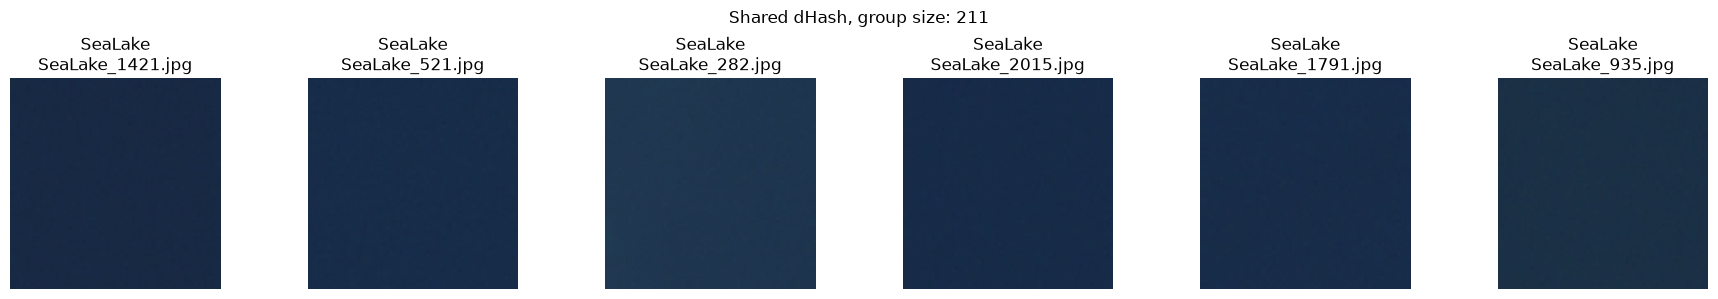

In [ ]:
import matplotlib.pyplot as plt

largest_group_id = candidates.loc[
    candidates["group_size"].idxmax(), "hash_group"
]

group = candidates.loc[
    candidates["hash_group"] == largest_group_id
]

examples = group.sample(
    n=min(6, len(group)),
    random_state=42,
)

fig, axes = plt.subplots(
    1, len(examples),
    figsize=(3 * len(examples), 3),
    squeeze=False,
)

for ax, record in zip(axes[0], examples.itertuples(index=False)):
    with Image.open(record.path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(
        f"{record.class_name}\n{Path(record.path).name}"
    )
    ax.axis("off")

fig.suptitle(f"Shared dHash, group size: {len(group)}")
plt.tight_layout()
plt.show()

Observamos que en superficies de agua con pocos detalles, los cambios suaves de azul producen huellas iguales al convertir a gris y reducir la imagen.

### Selección de imágenes representantes

Aplicamos el filtrado dentro de cada clase, con `MAX_HAMMING_DISTANCE = 12`. Conservamos la primera imagen y comparamos cada nueva huella con las ya conservadas. Si la distancia mínima es menor o igual al umbral, excluimos la nueva imagen del subconjunto. En caso contrario, la conservamos como representante.

En `filtered_inventory` guardamos las imágenes conservadas. En `exclusion_log` registramos cada imagen excluida, su representante (`matched_path`) y la distancia entre sus huellas.

In [26]:
MAX_HAMMING_DISTANCE = 12

working_inventory = inventory.reset_index(drop=True)

keep_mask = np.zeros(len(working_inventory), dtype=bool)
excluded_records = []

for class_name, class_rows in tqdm(
    working_inventory.groupby("class_name", sort=True),
    desc="Filtering classes",
):
    retained_indices = []

    for image_idx in class_rows.index:
        if retained_indices:
            distances = np.count_nonzero(
                hashes[retained_indices] != hashes[image_idx],
                axis=1,
            )

            nearest_position = int(distances.argmin())
            nearest_distance = int(distances[nearest_position])

            if nearest_distance <= MAX_HAMMING_DISTANCE:
                retained_idx = retained_indices[nearest_position]

                excluded_records.append({
                    "path": working_inventory.at[image_idx, "path"],
                    "class_name": class_name,
                    "matched_path": working_inventory.at[
                        retained_idx, "path"
                    ],
                    "hamming_distance": nearest_distance,
                })

                continue

        retained_indices.append(image_idx)
        keep_mask[image_idx] = True

filtered_inventory = (
    working_inventory.loc[keep_mask]
    .copy()
    .reset_index(drop=True)
)

exclusion_log = pd.DataFrame(
    excluded_records,
    columns=[
        "path",
        "class_name",
        "matched_path",
        "hamming_distance",
    ],
)

Filtering classes: 100%|██████████| 10/10 [00:01<00:00,  7.20it/s]


### Reducción obtenida por clase

Comparamos el número de imágenes antes y después del filtrado. La columna `excluded` nos permite ver qué clases se reducen más y comprobar si todavía disponemos de 800 imágenes por clase.


In [27]:
reduction_summary = pd.concat(
    [
        working_inventory.groupby("class_name")
        .size()
        .rename("before"),

        filtered_inventory.groupby("class_name")
        .size()
        .rename("after"),
    ],
    axis=1,
).fillna(0).astype(int)

reduction_summary["excluded"] = (
    reduction_summary["before"] - reduction_summary["after"]
)

display(reduction_summary)
print("Remaining images:", len(filtered_inventory))
print("Excluded images:", len(exclusion_log))

,before,after,excluded
class_name,,,
AnnualCrop,3000,2948,52
Forest,3000,2919,81
HerbaceousVegetation,3000,2994,6
Highway,2500,2488,12
Industrial,2500,2489,11
Pasture,2000,1994,6
PermanentCrop,2500,2495,5
Residential,3000,2998,2
River,2500,2408,92


Remaining images: 24861
Excluded images: 2139


## Muestreo Aleatorio

En la ejecución guardada con umbral 12 conservamos **24.861 imágenes** y excluimos 2.139, de las cuales 1.872 pertenecen a SeaLake. El resultado es compatible con la baja variación de los patrones de intensidad observados en muchos parches de agua. En las demás clases encontramos menos coincidencias según dHash.

Como todas las clases conservan más de 800 imágenes, seleccionamos **800 por clase** desde `filtered_inventory`.

Hacemos un muestreamos sin reemplazo para que ninguna imagen se selecciona dos veces. Fijamos `RANDOM_SEED = 42` para repetir la selección. Guardamos las 8.000 imágenes elegidas en `selected_inventory`.

In [30]:
IMAGES_PER_CLASS = 800
RANDOM_SEED = 42

remaining_counts = filtered_inventory.groupby("class_name").size()

selected_inventory = (
    filtered_inventory.groupby("class_name")
    .sample(
        n=IMAGES_PER_CLASS,
        replace=False,
        random_state=RANDOM_SEED,
    )
    .sort_values(["class_name", "path"])
    .reset_index(drop=True)
)

display(selected_inventory.groupby("class_name").size())
print("Selected images:", len(selected_inventory))

class_name
AnnualCrop              800
Forest                  800
HerbaceousVegetation    800
Highway                 800
Industrial              800
Pasture                 800
PermanentCrop           800
Residential             800
River                   800
SeaLake                 800
dtype: int64

Selected images: 8000


### Copia de las imágenes seleccionadas

Copiamos únicamente las imágenes de `selected_inventory` a `data/EuroSAT_RGB_800/`, manteniendo una subcarpeta por clase.

In [ ]:
from pathlib import Path
import shutil

from tqdm.auto import tqdm

OUTPUT_DIR = Path("data/EuroSAT_RGB_800")

if OUTPUT_DIR.exists():
    raise FileExistsError(
        f"Output directory already exists: {OUTPUT_DIR.resolve()}"
    )

OUTPUT_DIR.mkdir(parents=True)

for record in tqdm(
    selected_inventory.itertuples(index=False),
    total=len(selected_inventory),
    desc="Copying selected images",
):
    source_path = Path(record.path)
    destination_dir = OUTPUT_DIR / record.class_name
    destination_dir.mkdir(exist_ok=True)

    destination_path = destination_dir / source_path.name
    shutil.copy2(source_path, destination_path)

print("Output directory:", OUTPUT_DIR.resolve())
print("Copied images:", len(list(OUTPUT_DIR.glob("*/*.jpg"))))

Copying selected images: 100%|██████████| 8000/8000 [00:02<00:00, 3669.51it/s]

Output directory: /Users/antonpg/Documents/UPM/Ciencia de datos/4. Cuarto Curso/Primer Semestre/Algoritmos y Arquitecturas para Procesado de Imágenes/Proyecto-AAPI/data/EuroSAT_RGB_800
Copied images: 8000


In [32]:
archive_path = shutil.make_archive(
    base_name=str(OUTPUT_DIR),
    format="zip",
    root_dir=str(OUTPUT_DIR.parent),
    base_dir=OUTPUT_DIR.name,
)

archive_path = Path(archive_path)

print("Archive:", archive_path.resolve())
print(f"Archive size: {archive_path.stat().st_size / 1024**2:.2f} MiB")

Archive: /Users/antonpg/Documents/UPM/Ciencia de datos/4. Cuarto Curso/Primer Semestre/Algoritmos y Arquitecturas para Procesado de Imágenes/Proyecto-AAPI/data/EuroSAT_RGB_800.zip
Archive size: 26.79 MiB
